In [1]:
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from Protein_Sequence_Based_Prediction_of_Folding_Kinetics import(
    fetch_dataset,
    validate_dataset
)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

In [5]:
# -------------------------------
# Import data
# -------------------------------
data = fetch_dataset("analysis_dataset.sql")
report = validate_dataset(data)

# Ensure the one-to-one relationship established for measurement_id
assert data["measurement_id"].is_unique
assert len(data) == data["measurement_id"].nunique()

report

{'rows': 4839,
 'unique_measurements': 4839,
 'duplicate_measurement_ids': 0,
 'unique_proteins': 61,
 'unique_mutations': 1338,
 'missing_target': 766,
 'missing_reference_context': 1525,
 'missing_mutation_context': 1525}

In [4]:
# Explore data columns with most missing data
data.isna().mean().sort_values(ascending=False).head(15)

beta_t               0.972308
additives            0.828718
ec_number            0.783795
ddgkin_h2o           0.439179
dg_kin_h2o           0.346256
reference_context    0.320205
mutation_context     0.320205
dln_ku_h2o           0.281846
dln_kf_h2o           0.228513
mf                   0.219692
ln_ku_h2o            0.207795
mu                   0.165744
ln_kf_h2o            0.157128
reversibility        0.130051
cath                 0.095179
dtype: float64

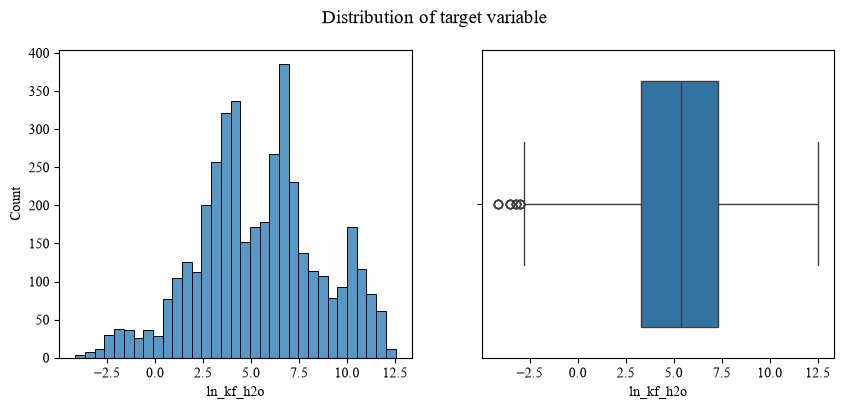

In [5]:
# Explore distribution of target variable
fig, ax = plt.subplots(1, 2, figsize = (10, 4))

sns.histplot(data = data, x = 'ln_kf_h2o', ax = ax[0])
sns.boxplot(data = data, x = 'ln_kf_h2o', ax = ax[1])
fig.suptitle('Distribution of target variable', fontsize = 14)
plt.show()

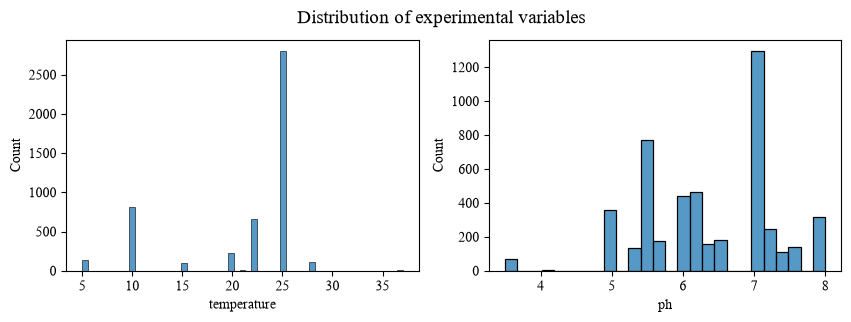

In [6]:
# Explore the applied methodologies
fig, ax = plt.subplots(1, 2, figsize = (10, 3))

sns.histplot(data = data, x = 'temperature', ax = ax[0])
sns.histplot(data = data, x = 'ph', ax = ax[1])
fig.suptitle('Distribution of experimental variables', fontsize = 14)
plt.show()

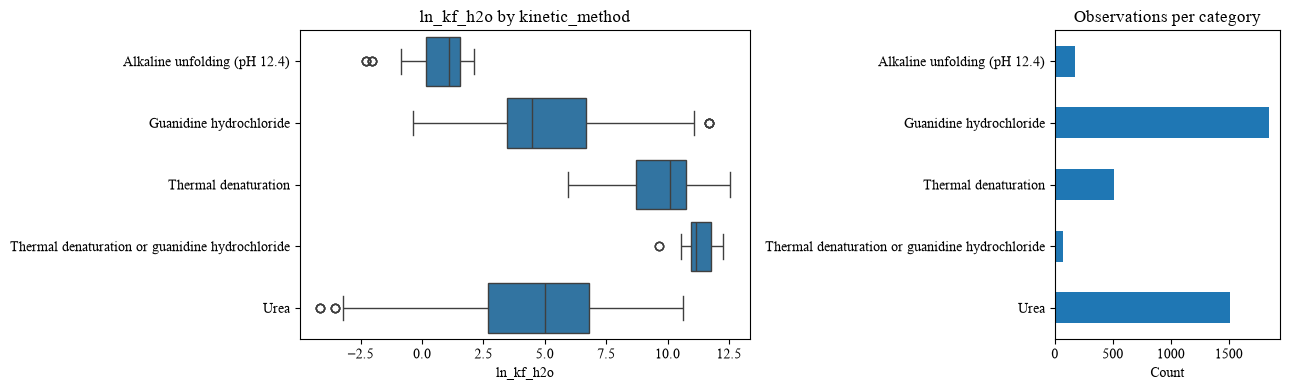

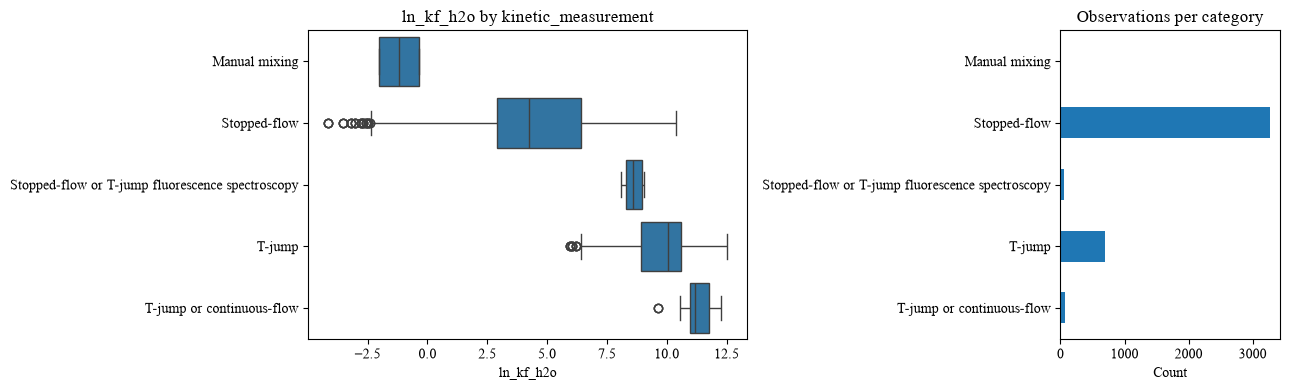

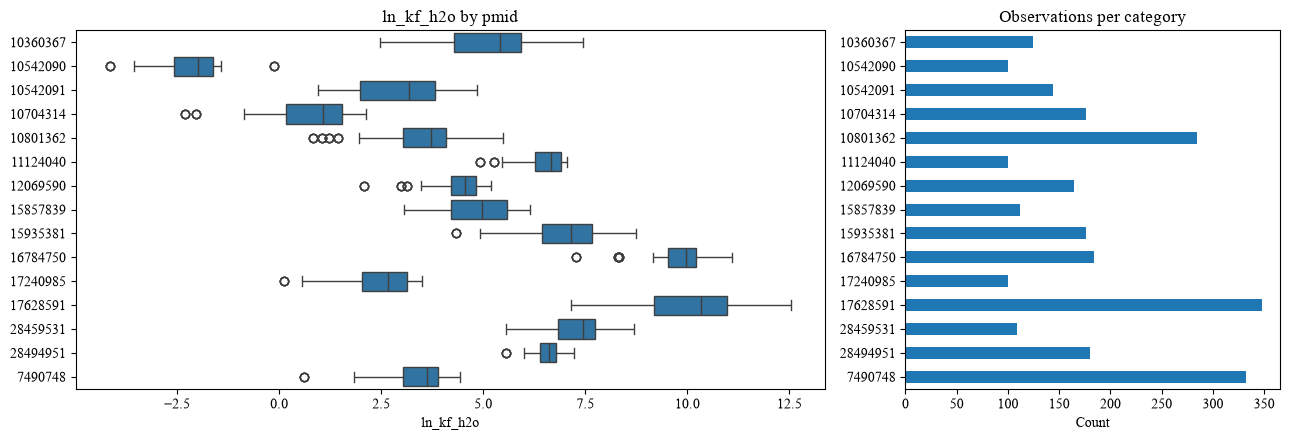

In [7]:
def plot_category_effect(data, category, target='ln_kf_h2o', min_count=10, top_n=15):
    plot_df = data[[category, target]].dropna().copy()

    # Keep sufficiently represented categories and limit very long plots.
    counts = plot_df[category].value_counts()
    categories = counts[counts >= min_count].head(top_n).index
    plot_df = plot_df[plot_df[category].isin(categories)]

    if plot_df.empty:
        print(f"No categories in {category!r} meet the minimum count.")
        return

    order = (
        plot_df.groupby(category)[target]
        .median()
        .sort_index()
        .index
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(13, max(4, len(order) * 0.3)),
        gridspec_kw={"width_ratios": [2, 1]}
    )

    sns.boxplot(data=plot_df, x=target, y=category, order=order, ax=axes[0])
    axes[0].set_title(f"{target} by {category}")
    axes[0].set_ylabel("")

    count_order = plot_df[category].value_counts().sort_index(ascending = False)
    count_order.plot.barh(ax=axes[1])
    axes[1].set_title("Observations per category")
    axes[1].set_xlabel("Count")
    axes[1].set_ylabel("")

    fig.tight_layout()
    plt.show()


plot_category_effect(data, "kinetic_method")
plot_category_effect(data, "kinetic_measurement")
plot_category_effect(
    data,
    category="pmid",
    min_count=10,
    top_n=15,
)

In [8]:
# Explore proteins and mutations pr. experimental category
data_by_experiment = data.groupby(['kinetic_method', 'kinetic_measurement']).agg(
    unique_proteins = ('protein_id', 'nunique'),
    unique_mutations = ('mutation_id', 'nunique')
)
print('\n', data_by_experiment)


                                                                                                   unique_proteins  \
kinetic_method                                  kinetic_measurement                                                 
Alkaline unfolding (pH 12.4)                    Stopped-flow                                                    1   
Guanidine hydrochloride                         Manual mixing                                                   1   
                                                Stopped-flow                                                   26   
                                                Stopped-flow or T-jump fluorescence spectroscopy                1   
                                                T-jump                                                          1   
Thermal denaturation                            T-jump                                                          9   
Thermal denaturation or guanidine hydrochloride T-jump or cont

In [9]:
# For numeric variables: Explore coverage, spread, and association with target
for col in ["temperature", "ph"]:
    subset = data[[col, 'ln_kf_h2o']].dropna()

    print(f"\n{col}")
    print(f"Observations: {len(subset)}")
    print(f"Unique values: {subset[col].nunique()}")
    print(f"Spearman correlation: "
          f"{subset[col].corr(subset['ln_kf_h2o'], method='spearman'):.3f}")

# For categorical variables: Explore group-level variation
for col in ["kinetic_method", "kinetic_measurement", "pmid"]:
    summary = (
        data.dropna(subset=[col, 'ln_kf_h2o'])
        .groupby(col)['ln_kf_h2o']
        .agg(["count", "median", "mean", "std"])
        .sort_values("count", ascending=False)
    )

    print(f"\n{col}")
    print(summary.head(15).round(3))


temperature
Observations: 4109
Unique values: 9
Spearman correlation: -0.292

ph
Observations: 4109
Unique values: 17
Spearman correlation: -0.101

kinetic_method
                                                 count median       mean  \
kinetic_method                                                             
Guanidine hydrochloride                           1849   4.47   5.185403   
Urea                                              1507   5.01   4.487405   
Thermal denaturation                               507  10.09   9.715562   
Alkaline unfolding (pH 12.4)                       176   1.08   0.725682   
Thermal denaturation or guanidine hydrochloride     70  11.16  11.273714   

                                                   std  
kinetic_method                                          
Guanidine hydrochloride                          2.343  
Urea                                             2.957  
Thermal denaturation                             1.477  
Alkaline unfolding

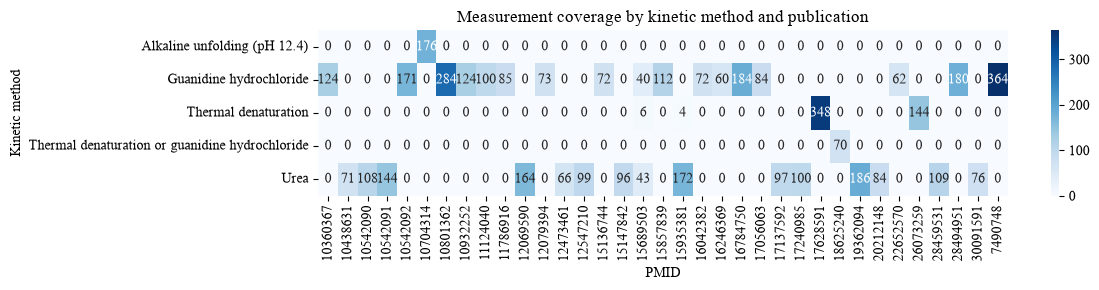

In [10]:
coverage = pd.crosstab(data["kinetic_method"], data["pmid"])

# Keep the most represented methods and publications for readability.
top_methods = data["kinetic_method"].value_counts().head(10).index
top_pmids = data["pmid"].value_counts().head(35).index

coverage = coverage.loc[
    coverage.index.intersection(top_methods),
    coverage.columns.intersection(top_pmids),
]

plt.figure(figsize=(12, 3))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues")
plt.title("Measurement coverage by kinetic method and publication")
plt.xlabel("PMID")
plt.ylabel("Kinetic method")
plt.tight_layout()
plt.show()

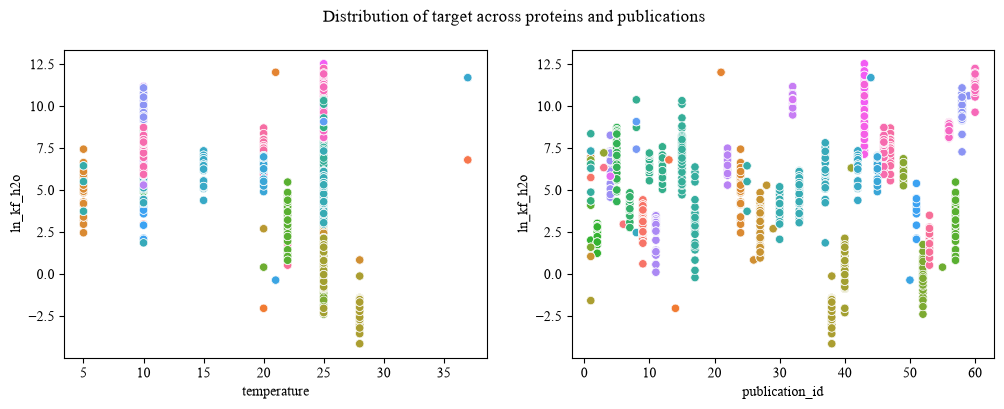

In [11]:
fig, ax = plt.subplots(1, 2, figsize = (12, 4))
sns.scatterplot(data = data, y = 'ln_kf_h2o', x = 'temperature', hue = 'protein_name', ax = ax[0], legend = False)
sns.scatterplot(data = data, y = 'ln_kf_h2o', x = 'publication_id', hue = 'protein_name', ax = ax[1], legend = False)
fig.suptitle('Distribution of target across proteins and publications')
plt.show()